# 03. Fine-tune FinBERT (or any BERT-style model)

Fine-tunes a 3-way hawkish / dovish / neutral classifier on the labeled FOMC sentences and evaluates under the leak-free schemes from `src/prepare_splits.py`:

| scheme | train | test |
|---|---|---|
| `time` | year <= 2018 | year > 2018 |
| `grouped` | 4 folds of documents | the 5th fold (no `doc_id` in both) |
| `walk` | everything before a 2-year block | that block (expanding window) |

Each scheme is reported overall and for **minutes sentences only**, since minutes are what we score later. The dataset's official split leaks (each test sentence's document is also in train), so it is not used here.

To run RoBERTa instead, change `MODEL_NAME` (e.g. `roberta-base`) and `TAG`. Do not use `gtfintechlab/FOMC-RoBERTa` as a benchmark here; it was trained on this data.

Runtime: GPU (T4). Roughly a minute per fold per seed.

In [3]:
# Colab: clone the repo and rebuild the processed data (raw and processed data are not in git)
import os
if not os.path.exists("DSA495-Fed-Reader") and not os.path.exists("src"):
    !git clone https://github.com/kgpai97-lab/DSA495-Fed-Reader.git
if os.path.exists("DSA495-Fed-Reader"):
    %cd DSA495-Fed-Reader
!git pull
!pip install -q -r requirements.txt
!python src/load_fomc_dataset.py
!python src/recover_metadata.py
!python src/flag_sentences.py
!python src/prepare_splits.py

Cloning into 'DSA495-Fed-Reader'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 47 (delta 16), reused 29 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 222.20 KiB | 4.27 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/DSA495-Fed-Reader
Already up to date.
README.md: 100% 2.00k/2.00k [00:00<00:00, 4.38MB/s]
train.csv: 100% 423k/423k [00:00<00:00, 103MB/s]
test.csv: 100% 104k/104k [00:00<00:00, 99.7MB/s]
Generating train split: 100% 1984/1984 [00:00<00:00, 44140.73 examples/s]
Generating test split: 100% 496/496 [00:00<00:00, 102881.89 examples/s]
saved data/raw/fomc_communication_train.csv (1984 rows)
saved data/raw/fomc_communication_test.csv (496 rows)
saved results/dataset_summary.md

# Dataset summary: `gtfintechlab/fomc_communication`

Generated by `src/load_fomc_dataset.py`.

## Fields
`index`, `sentence`, `year`, `label`, `orig_index`

## Label m

In [4]:
import sys
sys.path.insert(0, "src")
import random, numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from tone_eval import load_splits, score_table, LABELS, RESULTS_DIR

MODEL_NAME = "ProsusAI/finbert"
TAG = "finbert"
SCHEMES = ["time", "grouped", "walk"]
SEEDS = [495]            # add seeds (e.g. [495, 1, 2]) for variance estimates
EPOCHS, LR, BATCH, MAX_LEN, WARMUP = 4, 2e-5, 16, 128, 0.1   # fixed, not tuned on test data

df = load_splits()
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
print(len(df), "sentences;", device)

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

2202 sentences; cuda


In [5]:
def folds(scheme):
    """Yield (fold_name, train_row_ids, test_row_ids)."""
    if scheme == "time":
        yield "time", df.index[df["time_split"] == "train"], df.index[df["time_split"] == "test"]
    elif scheme == "grouped":
        for f in sorted(df["fold_grouped"].unique()):
            yield f"grouped{f}", df.index[df["fold_grouped"] != f], df.index[df["fold_grouped"] == f]
    elif scheme == "walk":
        for f in sorted(df.loc[df["walk_fold"] >= 0, "walk_fold"].unique()):
            test = df.index[df["walk_fold"] == f]
            first = df.loc[test, "date"].min()
            yield f"walk{f}", df.index[df["date"] < first], test


def encode(ids):
    enc = tok(df.loc[ids, "sentence"].tolist(), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    return list(zip(enc["input_ids"], enc["attention_mask"], torch.tensor(df.loc[ids, "label"].values)))


def collate(batch):
    ids, mask, y = zip(*batch)
    return torch.stack(ids), torch.stack(mask), torch.stack(y)


def new_model():
    m = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)},
        ignore_mismatched_sizes=True)
    # FinBERT ships a 3-way sentiment head in a different label order; re-initialize it
    # so no positive/negative meaning is carried into hawkish/dovish
    for mod in m.classifier.modules():
        if isinstance(mod, torch.nn.Linear):
            mod.weight.data.normal_(0, m.config.initializer_range)
            mod.bias.data.zero_()
    return m.to(device)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

In [6]:
def run_fold(train_ids, test_ids, seed):
    set_seed(seed)
    model = new_model()
    train_dl = DataLoader(encode(train_ids), batch_size=BATCH, shuffle=True, collate_fn=collate)
    test_dl = DataLoader(encode(test_ids), batch_size=64, collate_fn=collate)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * len(train_dl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    for _ in range(EPOCHS):
        model.train()
        for ids, mask, y in train_dl:
            loss = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
    model.eval(); probs = []
    with torch.no_grad():
        for ids, mask, _ in test_dl:
            probs.append(torch.softmax(model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits, -1).cpu().numpy())
    del model; torch.cuda.empty_cache()
    return np.vstack(probs)


all_preds = {}
for scheme in SCHEMES:
    parts = []
    for seed in SEEDS:
        for name, tr, te in folds(scheme):
            p = run_fold(tr, te, seed)
            out = df.loc[te, ["label", "doc_type", "year"]].copy()
            out[["p_dovish", "p_hawkish", "p_neutral"]] = p
            out["pred"] = p.argmax(1); out["fold"] = name; out["seed"] = seed
            parts.append(out)
            print(f"{scheme:8s} {name:9s} seed={seed} n_train={len(tr)} n_test={len(te)} acc={(out.pred == out.label).mean():.3f}")
    all_preds[scheme] = pd.concat(parts)

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

time     time      seed=495 n_train=1714 n_test=488 acc=0.590


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

grouped  grouped0  seed=495 n_train=1751 n_test=451 acc=0.647


... (16 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

walk     walk4     seed=495 n_train=1818 n_test=260 acc=0.619


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

walk     walk5     seed=495 n_train=2078 n_test=124 acc=0.581


## Scores
With several seeds, scores are computed per seed and then averaged. For `grouped` and `walk`, scores pool all test folds.

In [7]:
rows = []
for scheme, preds in all_preds.items():
    for seed, part in preds.groupby("seed"):
        t = score_table(part, f"{TAG} ({scheme})"); t["seed"] = seed; rows.append(t)
scores = pd.concat(rows)
scores.groupby(["model", "subset"])[["n", "accuracy", "macro_f1", "weighted_f1"]].mean().round(3)

n  accuracy  macro_f1
model             subset                             
finbert (grouped) all      2202.0     0.635     0.613
                  minutes   935.0     0.605     0.605
finbert (time)    all       488.0     0.590     0.573
                  minutes    98.0     0.592     0.584
finbert (walk)    all       912.0     0.614     0.598
                  minutes   321.0     0.617     0.605

              precision    recall  f1-score   support

      dovish       0.52      0.50      0.51       133
     hawkish       0.54      0.53      0.54       139
     neutral       0.66      0.68      0.67       216

    accuracy                           0.59       488
   macro avg       0.57      0.57      0.57       488
weighted avg       0.59      0.59      0.59       488



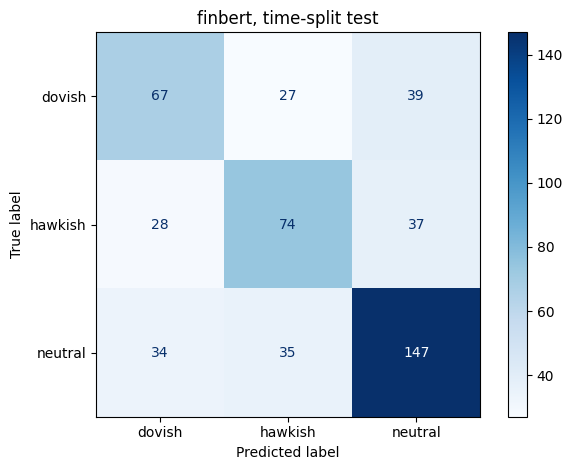

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

t = all_preds["time"]
print(classification_report(t["label"], t["pred"], target_names=LABELS, zero_division=0))
ConfusionMatrixDisplay.from_predictions(t["label"], t["pred"], display_labels=LABELS, cmap="Blues")
plt.title(f"{TAG}, time-split test"); plt.tight_layout(); plt.show()

In [9]:
# Walk-forward: does accuracy hold up as the test period moves later?
w = all_preds["walk"]
w.assign(correct=w["pred"] == w["label"]).groupby("fold")["correct"].agg(n="size", accuracy="mean").round(3)

,n,accuracy
fold,,
walk0,126,0.619
walk1,101,0.614
walk2,149,0.624
walk3,152,0.618
walk4,260,0.619
walk5,124,0.581


In [10]:
RESULTS_DIR.mkdir(exist_ok=True)
for scheme, preds in all_preds.items():
    preds.to_csv(RESULTS_DIR / f"preds_{TAG}_{scheme}.csv")
scores.to_csv(RESULTS_DIR / f"scores_{TAG}.csv", index=False)
print("saved to results/ (download from the Colab file browser and commit if wanted)")

saved to results/ (download from the Colab file browser and commit if wanted)
